# Beehive Honey Yield Prediction – Linear Regression

**Objective:** predict the **seasonal honey yield (kg)** of a beehive from colony and environment factors, comparing

1. **Simple Linear Regression** (one predictor: Flowering Area)
2. **Multiple Linear Regression** (four predictors: Colony Size, Flowering Area, Average Temperature, Rainfall)



## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
print("Libraries imported successfully")

Libraries imported successfully

## 2. Load the Dataset

In [2]:
df = pd.read_csv("Beehive_Honey_Yield.csv")
df.head()

,Hive_ID,Apiary_Type,Colony_Size_k,Flowering_Area_ha,Avg_Temp_C,Rainfall_mm,Honey_Yield_kg
0,3001,Stationary,50.5,9.0,29.6,87.2,53.4
1,3002,Migratory,39.2,7.7,25.0,44.3,43.1
2,3003,Migratory,67.6,7.0,30.2,54.5,59.0
3,3004,Stationary,50.6,9.3,26.2,32.2,57.8
4,3005,Organic,64.5,6.8,29.0,101.2,62.1


## 3. Data Exploration

In [3]:
print("Shape of dataset:", df.shape)
print()
df.info()

Shape of dataset: (500, 7)

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Hive_ID            500 non-null    int64  
 1   Apiary_Type        500 non-null    str    
 2   Colony_Size_k      500 non-null    float64
 3   Flowering_Area_ha  500 non-null    float64
 4   Avg_Temp_C         500 non-null    float64
 5   Rainfall_mm        500 non-null    float64
 6   Honey_Yield_kg     500 non-null    float64
dtypes: float64(5), int64(1), str(1)
memory usage: 27.5 KB

In [4]:
df.describe()

,Hive_ID,Colony_Size_k,Flowering_Area_ha,Avg_Temp_C,Rainfall_mm,Honey_Yield_kg
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,3250.500000,45.905600,9.326800,23.033800,79.436000,51.976400
std,144.481833,13.694026,4.836663,3.974013,40.721338,13.650496
min,3001.000000,15.000000,1.600000,12.400000,10.000000,18.200000
25%,3125.750000,36.600000,5.800000,20.200000,49.475000,42.050000
50%,3250.500000,45.150000,8.500000,22.800000,71.550000,51.000000
75%,3375.250000,55.300000,11.700000,25.800000,99.475000,59.500000
max,3500.000000,90.000000,29.400000,34.000000,231.300000,108.900000


## 4. Missing Values and Duplicates

In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
Hive_ID              0
Apiary_Type          0
Colony_Size_k        0
Flowering_Area_ha    0
Avg_Temp_C           0
Rainfall_mm          0
Honey_Yield_kg       0
dtype: int64

Duplicate rows: 0

## 5. Exploratory Data Analysis

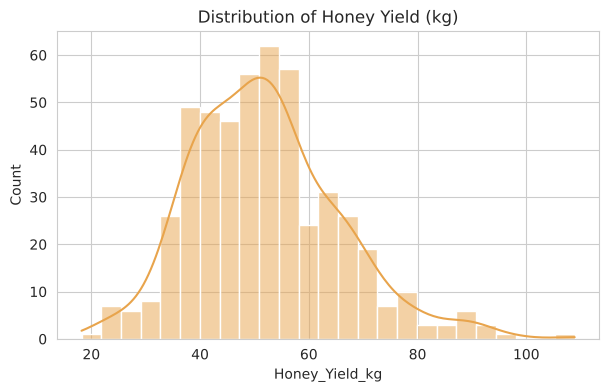

In [6]:
plt.figure(figsize=(7, 4))
sns.histplot(df["Honey_Yield_kg"], kde=True, bins=25, color="#E8A44C")
plt.title("Distribution of Honey Yield (kg)")
plt.show()

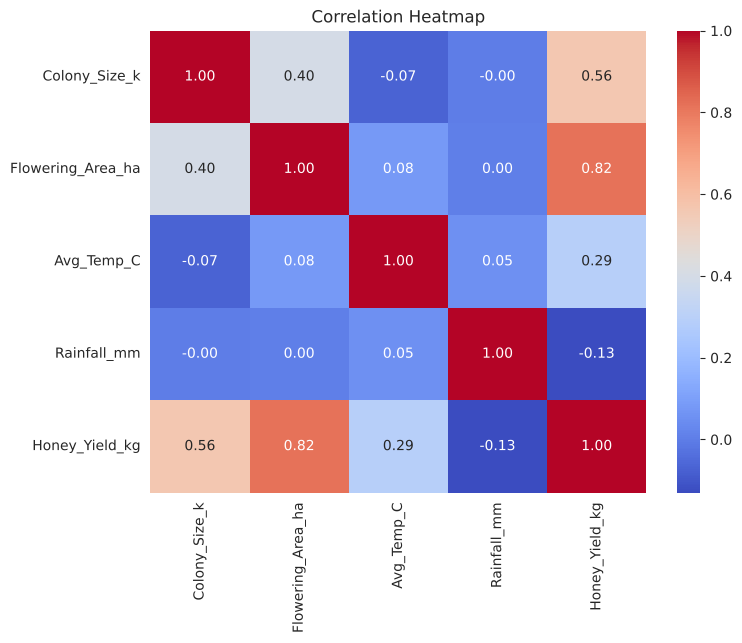

In [7]:
num_df = df.drop(columns=["Hive_ID", "Apiary_Type"])
plt.figure(figsize=(8, 6))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

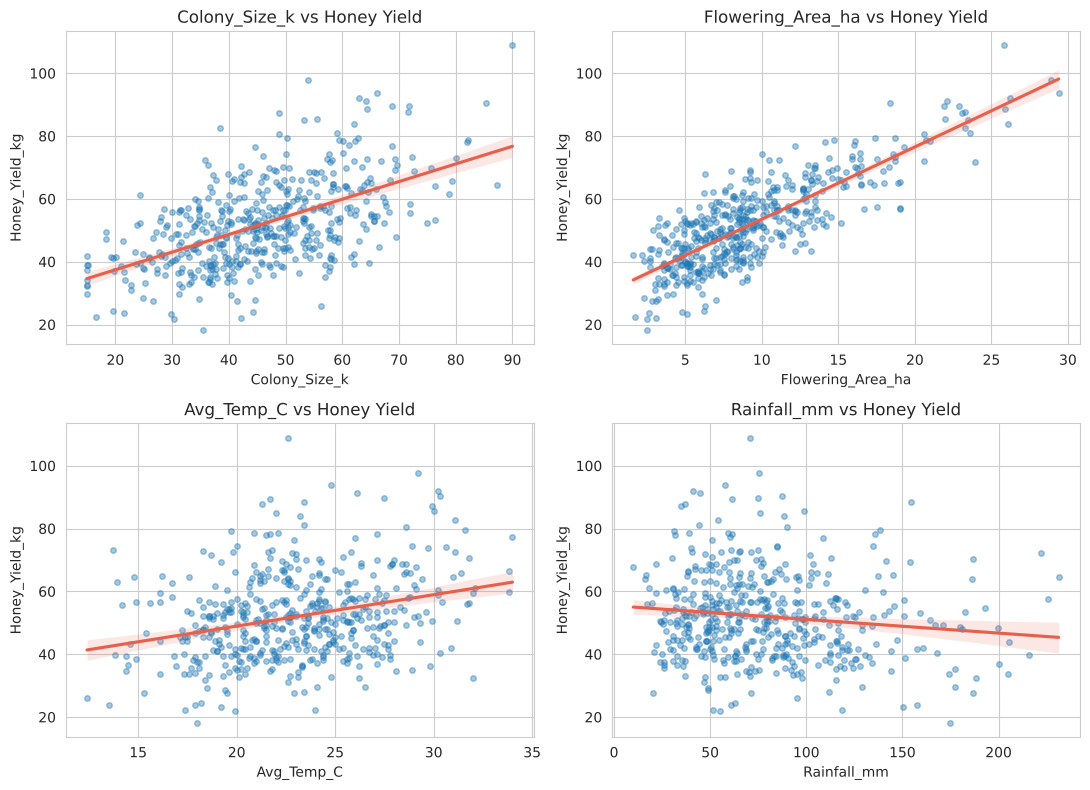

In [8]:
features = ["Colony_Size_k", "Flowering_Area_ha", "Avg_Temp_C", "Rainfall_mm"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), features):
    sns.regplot(data=df, x=col, y="Honey_Yield_kg", ax=ax,
                scatter_kws={"alpha": 0.4, "s": 16}, line_kws={"color": "#E8604C"})
    ax.set_title(f"{col} vs Honey Yield")
plt.tight_layout()
plt.show()

Apiary_Type
Migratory     52.49
Organic       52.40
Stationary    51.05
Name: Honey_Yield_kg, dtype: float64

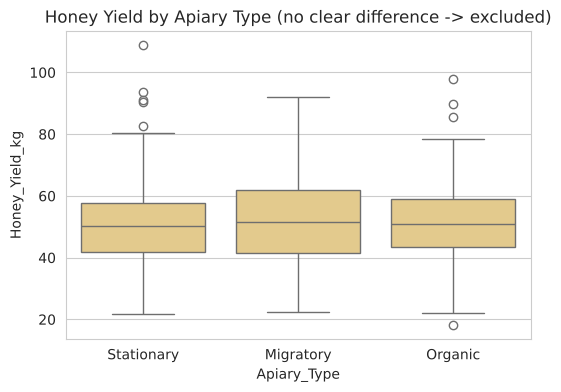

In [9]:
print(df.groupby("Apiary_Type")["Honey_Yield_kg"].mean().round(2))
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="Apiary_Type", y="Honey_Yield_kg", color="#F2D07E")
plt.title("Honey Yield by Apiary Type (no clear difference -> excluded)")
plt.show()

## 6. Select Independent and Dependent Variables
`Hive_ID` is an identifier and `Apiary_Type` shows no effect, so both are excluded.

In [10]:
X = df[features]
y = df["Honey_Yield_kg"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (500, 4)
y shape: (500,)

## 7. Train-Test Split (80% / 20%)

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 400
Testing samples : 100

## 8. Simple Linear Regression (Flowering Area only)
$Y = b_0 + b_1 X$

In [12]:
slr = LinearRegression()
slr.fit(X_train[["Flowering_Area_ha"]], y_train)
y_pred_slr = slr.predict(X_test[["Flowering_Area_ha"]])
print(f"Intercept (b0): {slr.intercept_:.3f}")
print(f"Slope (b1)    : {slr.coef_[0]:.3f}  -> each extra hectare of flowers adds ~{slr.coef_[0]:.2f} kg honey")

Intercept (b0): 30.036
Slope (b1)    : 2.337  -> each extra hectare of flowers adds ~2.34 kg honey

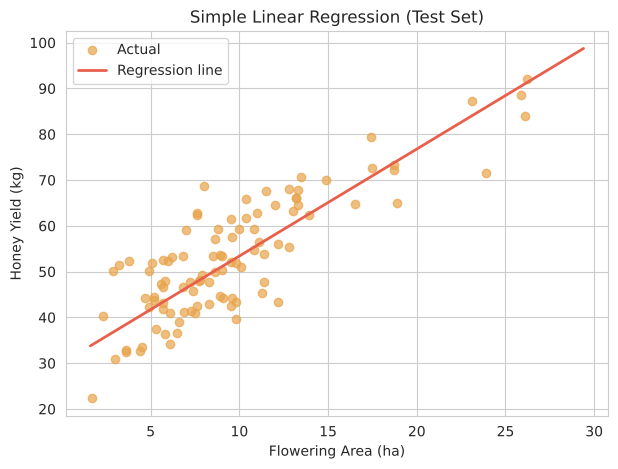

In [13]:
plt.figure(figsize=(7, 5))
plt.scatter(X_test["Flowering_Area_ha"], y_test, alpha=0.7, color="#E8A44C", label="Actual")
xs = pd.DataFrame({"Flowering_Area_ha": np.linspace(X["Flowering_Area_ha"].min(), X["Flowering_Area_ha"].max(), 100)})
plt.plot(xs, slr.predict(xs), color="#E8604C", linewidth=2, label="Regression line")
plt.xlabel("Flowering Area (ha)"); plt.ylabel("Honey Yield (kg)")
plt.title("Simple Linear Regression (Test Set)")
plt.legend()
plt.show()

## 9. Multiple Linear Regression (4 features)
$Y = b_0 + b_1X_1 + b_2X_2 + b_3X_3 + b_4X_4$

In [14]:
mlr = LinearRegression()
mlr.fit(X_train, y_train)
y_pred_mlr = mlr.predict(X_test)
print(f"Intercept (b0): {mlr.intercept_:.3f}")
coef_df = pd.DataFrame({"Feature": features, "Coefficient": mlr.coef_.round(3)})
coef_df

Intercept (b0): 0.859

,Feature,Coefficient
0,Colony_Size_k,0.319
1,Flowering_Area_ha,1.895
2,Avg_Temp_C,0.973
3,Rainfall_mm,-0.046


## 10. Model Evaluation

In [15]:
def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

m_slr = evaluate(y_test, y_pred_slr)
m_mlr = evaluate(y_test, y_pred_mlr)
comparison = pd.DataFrame({"Simple LR (Flowering Area)": m_slr, "Multiple LR (4 features)": m_mlr}).round(3)
comparison

,Simple LR (Flowering Area),Multiple LR (4 features)
MAE,5.964,4.265
MSE,53.780,28.491
RMSE,7.334,5.338
R2,0.693,0.838


In [16]:
cv_r2 = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")
print("5-fold R2 scores:", cv_r2.round(3))
print(f"Mean R2: {cv_r2.mean():.3f} (+/- {cv_r2.std():.3f})")

5-fold R2 scores: [0.758 0.839 0.752 0.86  0.818]
Mean R2: 0.805 (+/- 0.043)

## 11. Actual vs Predicted Values

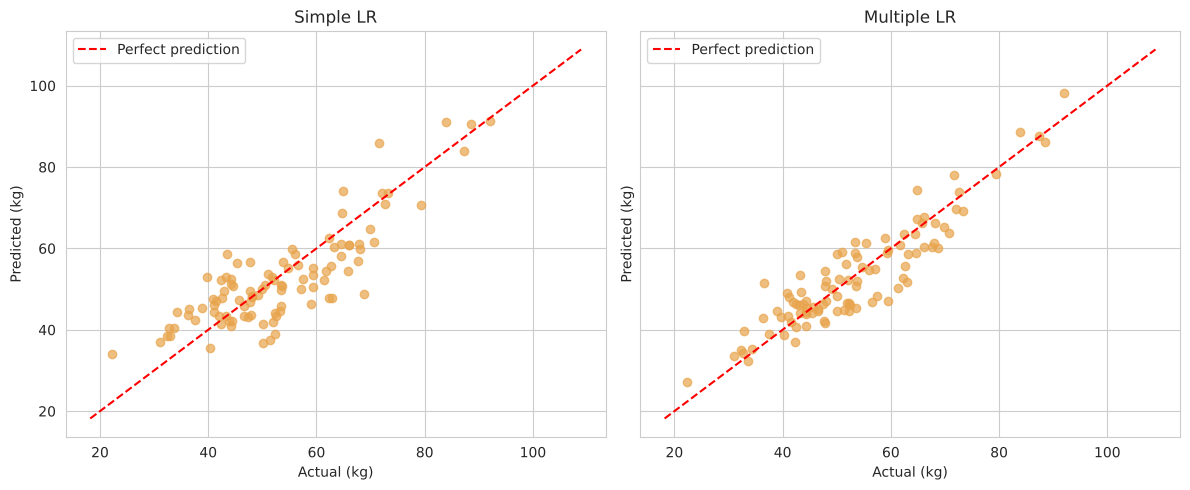

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, pred, title in [(axes[0], y_pred_slr, "Simple LR"), (axes[1], y_pred_mlr, "Multiple LR")]:
    ax.scatter(y_test, pred, alpha=0.7, color="#E8A44C")
    lims = [y.min(), y.max()]
    ax.plot(lims, lims, "r--", label="Perfect prediction")
    ax.set_xlabel("Actual (kg)"); ax.set_ylabel("Predicted (kg)"); ax.set_title(title); ax.legend()
plt.tight_layout()
plt.show()

## 12. Residual Analysis

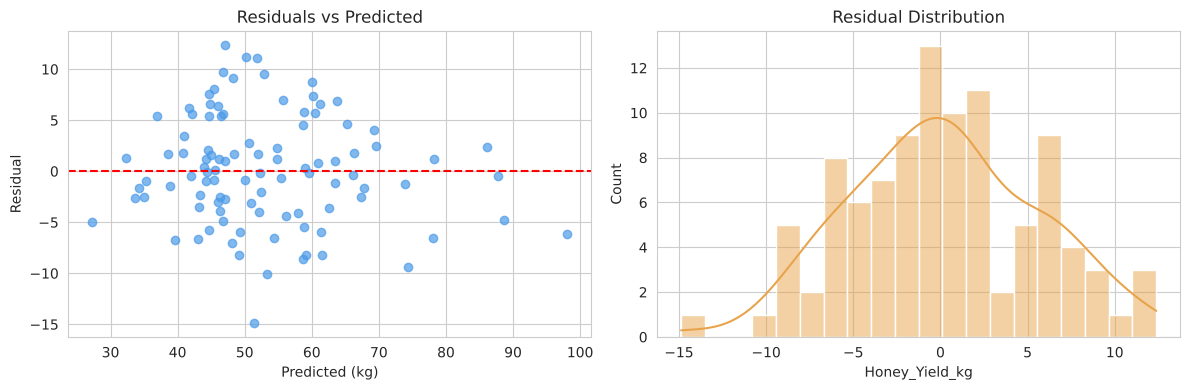

In [18]:
residuals = y_test - y_pred_mlr
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_pred_mlr, residuals, alpha=0.7, color="#4C9BE8")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted (kg)"); axes[0].set_ylabel("Residual"); axes[0].set_title("Residuals vs Predicted")
sns.histplot(residuals, kde=True, bins=20, ax=axes[1], color="#E8A44C")
axes[1].set_title("Residual Distribution")
plt.tight_layout()
plt.show()

## 13. Predict for New Hives

In [19]:
new_hives = pd.DataFrame({
    "Colony_Size_k": [30.0, 50.0, 75.0],
    "Flowering_Area_ha": [3.0, 8.0, 18.0],
    "Avg_Temp_C": [18.0, 23.0, 27.0],
    "Rainfall_mm": [120.0, 80.0, 50.0],
})
new_hives["Predicted_Honey_kg"] = mlr.predict(new_hives[features]).round(1)
new_hives

,Colony_Size_k,Flowering_Area_ha,Avg_Temp_C,Rainfall_mm,Predicted_Honey_kg
0,30.0,3.0,18.0,120.0,28.1
1,50.0,8.0,23.0,80.0,50.7
2,75.0,18.0,27.0,50.0,82.9


## 14. Conclusion
- Flowering area alone explains part of the yield; adding colony size, temperature and rainfall improves every metric.
- The fitted coefficients land close to the values used to simulate the data, which confirms the pipeline recovers a known relationship.
- Because the data is simulated, treat this as a template for the method; run it on real hive records for real conclusions.
- Next steps: Ridge/Lasso, interaction terms (colony size × forage), cross-validation tuning.